# Marketing Campaign Effectiveness Analysis

In this notebook we analyse **1,218 marketing campaigns** run in 2023 and 2024 to find out
which campaigns worked best, what makes a campaign convert, and where the marketing budget
should go next.

**Workflow:**
1. Load and explore the data
2. Clean the data (duplicates, text, data types, wrong values, outliers, missing values)
3. Transform the data (new columns, encoding, scaling)
4. Exploratory data analysis (EDA) with charts
5. Answer the business questions
6. Summary and recommendations

**Golden rule:** Inspect before cleaning, verify after cleaning.

### Words we will use a lot

| Word | Meaning | Formula |
|------|---------|---------|
| Impressions | how many times the ad was shown | |
| Clicks | how many times people clicked the ad | |
| Conversions | how many people bought / signed up | |
| CTR (click-through rate) | % of people who saw the ad and clicked | clicks / impressions x 100 |
| Conversion rate | % of clickers who converted | conversions / clicks x 100 |
| Response rate | % of people who saw the ad and converted | conversions / impressions x 100 |
| CPA (cost per acquisition) | money spent to get one customer | spend / conversions |
| ROI (return on investment) | profit compared to money spent | (revenue - spend) / spend x 100 |

## Step 0: Load the Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# one fixed colour for each channel, so a channel looks the same in every chart
channel_colors = {
    "Email": "tab:blue",
    "Search": "tab:orange",
    "Affiliate": "tab:green",
    "Social Media": "tab:red",
    "Influencer": "tab:purple",
    "Display": "tab:brown",
    "Video": "tab:pink",
}

df = pd.read_csv("../data/marketing_campaigns_raw.csv")

df.head()

,campaign_id,campaign_name,campaign_type,channel,region,target_audience,start_date,end_date,budget,spend,impressions,clicks,conversions,revenue,engagement_score
0,CMP-0542,Webinar - Search - NA,Lead Generation,Search,North America,Millennials (25-34),2023-07-26,2023-08-24,15300.0,15082.40,472928,10893.0,620.0,46771.25,6.0
1,CMP-0260,Free Trial - Display - EU,Lead Generation,Display,Europe,Gen Z (18-24),2023-07-20,2023-08-18,7850.0,7031.26,1909955,4291.0,71.0,4303.14,1.0
2,CMP-0044,First Look - Social Media - NA,Product Launch,Social Media,NaN,Gen Z (18-24),2023-07-12,2023-08-10,36650.0,30012.11,2529122,63621.0,1243.0,NaN,6.2
3,CMP-1009,Just Dropped - Video - NA,Product Launch,Video,North America,Gen Z (18-24),2023-04-25,2023-05-24,25500.0,23014.66,1245599,21484.0,267.0,22887.30,5.1
4,CMP-0585,Meet Us - Affiliate - NA,Awareness,Affiliate,North America,Boomers (45-64),2024-08-07,2024-09-05,14700.0,12167.01,1626772,NaN,259.0,25462.68,4.8


## Step 1: Explore the Data

Never clean blindly. First understand what we have.

In [2]:
df.shape   # (rows, columns)

(1218, 15)

In [3]:
df.info()   # types + non-null counts

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   campaign_id       1218 non-null   object 
 1   campaign_name     1218 non-null   object 
 2   campaign_type     1218 non-null   object 
 3   channel           1218 non-null   object 
 4   region            1192 non-null   object 
 5   target_audience   1182 non-null   object 
 6   start_date        1218 non-null   object 
 7   end_date          1203 non-null   object 
 8   budget            1187 non-null   object 
 9   spend             1218 non-null   float64
 10  impressions       1218 non-null   int64  
 11  clicks            1196 non-null   float64
 12  conversions       1205 non-null   float64
 13  revenue           1189 non-null   float64
 14  engagement_score  1173 non-null   float64
dtypes: float64(5), int64(1), object(9)
memory usage: 142.9+ KB


In [4]:
df.describe()   # statistics of numeric columns

,spend,impressions,clicks,conversions,revenue,engagement_score
count,1218.000000,1.218000e+03,1.196000e+03,1205.000000,1189.000000,1173.000000
mean,13329.329729,1.277834e+06,3.490638e+04,828.641494,56743.558839,5.616027
std,11023.107373,1.135909e+06,2.687878e+05,3462.092072,76151.831069,2.371064
min,-12168.570000,6.380300e+04,1.641000e+03,11.000000,716.610000,-1.000000
25%,5961.770000,4.998875e+05,8.965750e+03,189.000000,13188.420000,3.700000
50%,10389.510000,9.432935e+05,1.476050e+04,422.000000,32378.560000,5.300000
75%,16669.065000,1.684290e+06,2.491075e+04,838.000000,65682.930000,7.300000
max,86404.700000,9.255011e+06,6.683621e+06,111786.000000,709373.940000,12.500000


In [5]:
df.describe(include="object")   # statistics of text columns

,campaign_id,campaign_name,campaign_type,channel,region,target_audience,start_date,end_date,budget
count,1218,1218,1218,1218,1192,1182,1218,1203,1187
unique,1200,545,10,31,18,4,571,585,580
top,CMP-0543,Last Chance - Social Media - EU,Lead Generation,Social Media,North America,Millennials (25-34),2024-02-26,2023-07-14,5150.0
freq,2,9,246,223,354,427,6,8,10


**What we can already see:**
- `budget` is `object` (text), but it should be a number, so some values contain text.
- `start_date` and `end_date` are text, they should be dates.
- `spend` has a **negative** minimum, and `engagement_score` goes below 1 and above 10
  (it should be a 1-10 score).
- `channel` has 31 unique values and `region` has 18, but there should only be 7 channels
  and 5 regions. The same category is written in different ways.

### 1.1 Missing values

In [6]:
df.isna().sum()

campaign_id          0
campaign_name        0
campaign_type        0
channel              0
region              26
target_audience     36
start_date           0
end_date            15
budget              31
spend                0
impressions          0
clicks              22
conversions         13
revenue             29
engagement_score    45
dtype: int64

In [7]:
# as percentage (easier to decide what to do)
(df.isna().mean() * 100).round(1)

campaign_id         0.0
campaign_name       0.0
campaign_type       0.0
channel             0.0
region              2.1
target_audience     3.0
start_date          0.0
end_date            1.2
budget              2.5
spend               0.0
impressions         0.0
clicks              1.8
conversions         1.1
revenue             2.4
engagement_score    3.7
dtype: float64

### 1.2 Duplicates

In [8]:
df.duplicated().sum()

np.int64(18)

In [9]:
# look at the duplicated rows using loc
df.loc[df.duplicated(), ["campaign_id", "campaign_name", "spend"]].head()

,campaign_id,campaign_name,spend
450,CMP-0742,Meet Us - Email - EU,2961.81
526,CMP-0760,Newsletter Signup - Search - APAC,31232.76
735,CMP-0890,New Arrivals - Display - EU,15671.52
739,CMP-1140,Newsletter Signup - Display - NA,8011.95
793,CMP-0560,We Miss You - Search - MEA,6918.58


### 1.3 Messy text categories

In [10]:
print(df["channel"].nunique())
df["channel"].unique()

31


array(['Search', 'Display', 'Social Media ', 'Video', 'Affiliate',
       'social media', 'Social Media', 'Email', 'YouTube/Video',
       'display', 'Influencer', 'Social', 'VIDEO', 'search', 'email',
       'Affiliates', 'Display ', 'SEARCH', 'Search Ads', 'SocialMedia',
       'video', ' Email', 'affiliate', 'Display Ads', 'Paid Search',
       'influencer', 'E-mail', 'AFFILIATE', 'Influencer Marketing',
       'EMAIL', 'Influencers'], dtype=object)

In [11]:
print(df["region"].nunique())
df["region"].unique()

18


array(['North America', 'Europe', nan, 'Latin America', 'north america',
       'Asia Pacific', 'APAC', 'Middle East & Africa',
       'Middle East and Africa', 'Asia-Pacific', 'europe', 'asia pacific',
       'LATAM', 'North America ', 'Europe ', 'latin america',
       'N. America', 'EU', 'MEA'], dtype=object)

In [12]:
df["campaign_type"].unique()

array(['Lead Generation', 'Product Launch', 'Awareness', 'Retargeting',
       'Seasonal Promo', 'retargeting', 'seasonal promo',
       'product launch', 'awareness', 'lead generation'], dtype=object)

### 1.4 Values that are impossible in real life

In [13]:
# budget values written as text like "$12,500"
df.loc[df["budget"].str.contains("$", regex=False, na=False), ["campaign_id", "budget"]].head()

,campaign_id,budget
10,CMP-0559,"$11,450"
15,CMP-0523,"$6,450"
42,CMP-0865,"$3,850"
46,CMP-0416,"$27,750"
92,CMP-0786,"$15,050"


In [14]:
# spend can never be negative
df.loc[df["spend"] < 0, ["campaign_id", "spend"]]

,campaign_id,spend
402,CMP-0809,-8013.60
561,CMP-0178,-5852.95
711,CMP-1139,-9459.88
791,CMP-0488,-10789.07
1013,CMP-0233,-7507.01
1186,CMP-0687,-12168.57


In [15]:
# you cannot have more clicks than impressions
df.loc[df["clicks"] > df["impressions"], ["campaign_id", "impressions", "clicks"]]

,campaign_id,impressions,clicks
40,CMP-0045,2868818,3832626.0
100,CMP-0055,3757311,4792367.0
332,CMP-0543,429762,570711.0
423,CMP-0352,1394299,2011945.0
1091,CMP-0543,429762,570711.0
1164,CMP-0206,5158283,6683621.0


In [16]:
# you cannot have more conversions than clicks
df.loc[df["conversions"] > df["clicks"], ["campaign_id", "clicks", "conversions"]]

,campaign_id,clicks,conversions
410,CMP-0317,62439.0,111786.0
548,CMP-1174,18574.0,33504.0
583,CMP-1158,7048.0,11563.0
925,CMP-1064,5488.0,9565.0


In [17]:
# a campaign cannot end before it starts
df.loc[df["end_date"] < df["start_date"], ["campaign_id", "start_date", "end_date"]]

,campaign_id,start_date,end_date
88,CMP-0763,2024-02-04,2024-01-22
293,CMP-0674,2023-02-21,2023-02-08
355,CMP-0274,2023-10-11,2023-09-12
462,CMP-0030,2023-11-25,2023-10-27
723,CMP-0906,2023-07-06,2023-06-30
987,CMP-0153,2024-07-22,2024-07-09


In [18]:
# engagement score must be between 1 and 10
df.loc[(df["engagement_score"] < 1) | (df["engagement_score"] > 10), ["campaign_id", "engagement_score"]]

,campaign_id,engagement_score
42,CMP-0865,12.5
173,CMP-0436,-1.0
926,CMP-0172,-1.0
1085,CMP-0682,0.0


### 1.5 Problems found and the plan

| Problem | Plan |
|---------|------|
| 18 duplicate rows | Drop them |
| Same channel/region written in many ways (`email`, `E-mail`, `NA`, `EU` ...) | Make one standard name |
| `budget` stored as text with `$` and `,` | Remove the symbols, change to number |
| Dates stored as text, 6 campaigns with start and end swapped | Change to dates, swap them back |
| Negative spend | Typing mistake: make it positive |
| Clicks > impressions, conversions > clicks, score outside 1-10 | Wrong values: make them missing, then fill |
| Some budgets are much too big | Check with the IQR rule and fix the typing mistakes |
| Missing values in 8 columns (1-4 %) | Fill each column in a sensible way |

## Step 2: Clean the Data

### 2.1 Remove duplicates

In [19]:
print("Rows before:", len(df))

df = df.drop_duplicates()

print("Rows after:", len(df))
print("Duplicates after:", df.duplicated().sum())

Rows before: 1218
Rows after: 1200
Duplicates after: 0


### 2.2 Clean text categories

First remove extra spaces and make everything lower case, then use `replace` to change
every different spelling into one name, and finally make it Title Case again.

In [20]:
channel_fix = {
    "e-mail": "email",
    "social": "social media",
    "socialmedia": "social media",
    "paid search": "search",
    "search ads": "search",
    "display ads": "display",
    "youtube/video": "video",
    "influencers": "influencer",
    "influencer marketing": "influencer",
    "affiliates": "affiliate",
}

df["channel"] = df["channel"].str.strip().str.lower()
df["channel"] = df["channel"].replace(channel_fix)
df["channel"] = df["channel"].str.title()

df["channel"].value_counts()

channel
Social Media    248
Search          213
Email           207
Display         164
Video           128
Influencer      122
Affiliate       118
Name: count, dtype: int64

In [21]:
region_fix = {
    "na": "north america",
    "n. america": "north america",
    "eu": "europe",
    "apac": "asia pacific",
    "asia-pacific": "asia pacific",
    "latam": "latin america",
    "mea": "middle east & africa",
    "middle east and africa": "middle east & africa",
}

df["region"] = df["region"].str.strip().str.lower()
df["region"] = df["region"].replace(region_fix)
df["region"] = df["region"].str.title()

df["region"].value_counts()

region
North America           372
Europe                  338
Asia Pacific            225
Latin America           128
Middle East & Africa    111
Name: count, dtype: int64

In [22]:
df["campaign_type"] = df["campaign_type"].str.strip().str.title()

df["campaign_type"].value_counts()

campaign_type
Seasonal Promo     246
Retargeting        243
Awareness          243
Lead Generation    242
Product Launch     226
Name: count, dtype: int64

### 2.3 Fix data types

In [23]:
# remove "$" and "," from budget, then change it to a number
df["budget"] = df["budget"].str.replace("$", "", regex=False)
df["budget"] = df["budget"].str.replace(",", "", regex=False)
df["budget"] = df["budget"].astype(float)

# change text dates to real dates
df["start_date"] = pd.to_datetime(df["start_date"])
df["end_date"] = pd.to_datetime(df["end_date"])

df.dtypes

campaign_id                 object
campaign_name               object
campaign_type               object
channel                     object
region                      object
target_audience             object
start_date          datetime64[ns]
end_date            datetime64[ns]
budget                     float64
spend                      float64
impressions                  int64
clicks                     float64
conversions                float64
revenue                    float64
engagement_score           float64
dtype: object

### 2.4 Fix impossible values

In [24]:
# negative spend is a typing mistake, so take the positive value
df["spend"] = df["spend"].abs()

# swap start and end date back where they were entered the wrong way round
# (.values takes only the numbers, so pandas does not match the column names back)
swapped = df["end_date"] < df["start_date"]
df.loc[swapped, ["start_date", "end_date"]] = df.loc[swapped, ["end_date", "start_date"]].values

# these values cannot be trusted, so we make them missing and fill them later in 2.6
df.loc[df["clicks"] > df["impressions"], "clicks"] = np.nan
df.loc[df["conversions"] > df["clicks"], "conversions"] = np.nan
df.loc[(df["engagement_score"] < 1) | (df["engagement_score"] > 10), "engagement_score"] = np.nan

print("Negative spend left:", (df["spend"] < 0).sum())
print("End before start left:", (df["end_date"] < df["start_date"]).sum())

Negative spend left: 0
End before start left: 0


### 2.5 Handle outliers in budget

We use the IQR rule, same as we did with Fare in the Titanic data.

In [25]:
Q1 = df["budget"].quantile(0.25)
Q3 = df["budget"].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR

print("Q1:", Q1, " Q3:", Q3, " Upper limit:", round(upper, 2))
print("Outliers:", (df["budget"] > upper).sum())

Q1: 7050.0  Q3: 19737.5  Upper limit: 38768.75
Outliers: 68


In [26]:
# look at the outliers next to how much the campaign really spent
df.loc[df["budget"] > upper, ["campaign_id", "channel", "budget", "spend"]].sort_values("budget", ascending=False).head(15)

,campaign_id,channel,budget,spend
1075,CMP-0710,Search,3035000.0,25988.36
228,CMP-0414,Influencer,2875000.0,28927.19
519,CMP-0606,Video,2490000.0,20497.40
304,CMP-0243,Social Media,2355000.0,17562.02
333,CMP-1044,Display,1545000.0,12741.94
776,CMP-0926,Social Media,1485000.0,12062.96
39,CMP-0771,Social Media,1430000.0,14815.55
788,CMP-0189,Video,1370000.0,10743.02
995,CMP-0104,Affiliate,1250000.0,11324.75
1032,CMP-0641,Video,705000.0,7194.18


**Decision time.** Not every outlier is a mistake:
- Most of these campaigns have a big budget **and** a big spend. They are real big campaigns,
  so we keep them.
- A few have a budget about **100 times** bigger than their spend (for example a budget of
  2,450,000 with a spend of 18,715). Somebody typed two extra zeros.

So the rule is: if the budget is more than 20 times the spend, divide it by 100.

In [27]:
budget_before = df["budget"].copy()

typing_mistake = df["budget"] > df["spend"] * 20
print("Budgets fixed:", typing_mistake.sum())

df.loc[typing_mistake, "budget"] = df.loc[typing_mistake, "budget"] / 100

Budgets fixed: 11


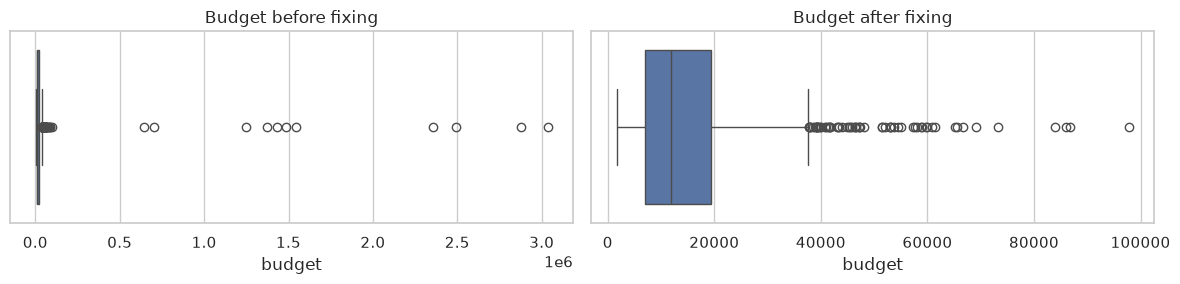

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))

sns.boxplot(x=budget_before, ax=axes[0])
axes[0].set_title("Budget before fixing")

sns.boxplot(x=df["budget"], ax=axes[1])
axes[1].set_title("Budget after fixing")

plt.tight_layout()
plt.savefig("../diagrams/01_budget_outliers.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.6 Handle missing values

In [29]:
df.isna().sum()

campaign_id          0
campaign_name        0
campaign_type        0
channel              0
region              26
target_audience     35
start_date           0
end_date            15
budget              30
spend                0
impressions          0
clicks              27
conversions         16
revenue             28
engagement_score    49
dtype: int64

**Decide and act**

| Column | Decision | Why |
|--------|----------|-----|
| `region`, `target_audience` | Fill with `"Unknown"` | Guessing a region could give wrong results |
| `end_date` | start date + median campaign length | Most campaigns run for a standard length |
| `budget` | spend / median (spend / budget) | Campaigns usually spend most of their budget |
| `clicks` | impressions x median CTR **of the same channel** | Each channel has its own CTR |
| `conversions` | clicks x median conversion rate **of the same channel** | Same reason |
| `revenue` | conversions x median revenue per conversion **of the same region** | Order value is different in each region |
| `engagement_score` | median **of the same channel** | |

**New learning: `groupby().transform("median")`**. Normal `groupby` gives one row per group.
`transform` gives the group's value back on **every row**, so we can use it to fill each row
with the median of its own channel.

In [30]:
# region and target audience
df["region"] = df["region"].fillna("Unknown")
df["target_audience"] = df["target_audience"].fillna("Unknown")

In [31]:
# end date = start date + median campaign length
length_days = (df["end_date"] - df["start_date"]).dt.days
median_days = length_days.median()
print("Median campaign length:", median_days, "days")

df.loc[df["end_date"].isna(), "end_date"] = df["start_date"] + pd.Timedelta(days=median_days)

Median campaign length: 20.0 days


In [32]:
# budget = spend / usual share of budget that gets spent
spend_share = (df["spend"] / df["budget"]).median()
print("Campaigns usually spend", round(spend_share * 100), "% of their budget")

df.loc[df["budget"].isna(), "budget"] = (df["spend"] / spend_share).round(-1)

Campaigns usually spend 89 % of their budget


In [33]:
# clicks = impressions x median CTR of the same channel
df["ctr_temp"] = df["clicks"] / df["impressions"]
df["channel_ctr"] = df.groupby("channel")["ctr_temp"].transform("median")

df.loc[df["clicks"].isna(), "clicks"] = (df["impressions"] * df["channel_ctr"]).round()

In [34]:
# conversions = clicks x median conversion rate of the same channel
df["conv_temp"] = df["conversions"] / df["clicks"]
df["channel_conv"] = df.groupby("channel")["conv_temp"].transform("median")

df.loc[df["conversions"].isna(), "conversions"] = (df["clicks"] * df["channel_conv"]).round()

In [35]:
# revenue = conversions x median revenue per conversion of the same region
df["rev_temp"] = df["revenue"] / df["conversions"]
df["region_rev"] = df.groupby("region")["rev_temp"].transform("median")

df.loc[df["revenue"].isna(), "revenue"] = (df["conversions"] * df["region_rev"]).round(2)

In [36]:
# engagement score = median of the same channel
df["channel_eng"] = df.groupby("channel")["engagement_score"].transform("median")
df.loc[df["engagement_score"].isna(), "engagement_score"] = df["channel_eng"]

In [37]:
# remove the helper columns, we do not need them anymore
df = df.drop(columns=["ctr_temp", "channel_ctr", "conv_temp", "channel_conv",
                      "rev_temp", "region_rev", "channel_eng"])

# clicks and conversions are counts, so make them whole numbers
df["clicks"] = df["clicks"].astype(int)
df["conversions"] = df["conversions"].astype(int)

# verify: no missing values should remain
df.isna().sum()

campaign_id         0
campaign_name       0
campaign_type       0
channel             0
region              0
target_audience     0
start_date          0
end_date            0
budget              0
spend               0
impressions         0
clicks              0
conversions         0
revenue             0
engagement_score    0
dtype: int64

## Step 3: Transform the Data

### 3.1 Create new columns

In [38]:
# campaign length
df["duration_days"] = (df["end_date"] - df["start_date"]).dt.days + 1

# performance (in %)
df["ctr"] = (df["clicks"] / df["impressions"] * 100).round(2)
df["conversion_rate"] = (df["conversions"] / df["clicks"] * 100).round(2)
df["response_rate"] = (df["conversions"] / df["impressions"] * 100).round(4)

# cost and money
df["cpc"] = (df["spend"] / df["clicks"]).round(2)          # cost per click
df["cpa"] = (df["spend"] / df["conversions"]).round(2)     # cost per acquisition (one customer)
df["profit"] = (df["revenue"] - df["spend"]).round(2)
df["roi"] = (df["profit"] / df["spend"] * 100).round(1)    # in %

# time
df["year"] = df["start_date"].dt.year
df["month"] = df["start_date"].dt.month
df["month_name"] = df["start_date"].dt.month_name()
df["quarter"] = df["start_date"].dt.quarter

df[["campaign_id", "channel", "duration_days", "ctr", "conversion_rate", "cpa", "roi"]].head()

,campaign_id,channel,duration_days,ctr,conversion_rate,cpa,roi
0,CMP-0542,Search,30,2.30,5.69,24.33,210.1
1,CMP-0260,Display,30,0.22,1.65,99.03,-38.8
2,CMP-0044,Social Media,30,2.52,1.95,24.14,283.4
3,CMP-1009,Video,30,1.72,1.24,86.20,-0.6
4,CMP-0585,Affiliate,30,1.29,1.23,46.98,109.3


In [39]:
# label campaign length into groups using loc
df.loc[df["duration_days"] <= 14, "length_group"] = "1-2 weeks"
df.loc[(df["duration_days"] > 14) & (df["duration_days"] <= 30), "length_group"] = "3-4 weeks"
df.loc[(df["duration_days"] > 30) & (df["duration_days"] <= 60), "length_group"] = "1-2 months"
df.loc[df["duration_days"] > 60, "length_group"] = "2+ months"

df["length_group"].value_counts()

length_group
1-2 weeks     460
3-4 weeks     452
1-2 months    228
2+ months      60
Name: count, dtype: int64

### 3.2 Outliers in response rate

Every channel has a different normal response rate (email is much higher than display),
so we look at it per channel with a boxplot.

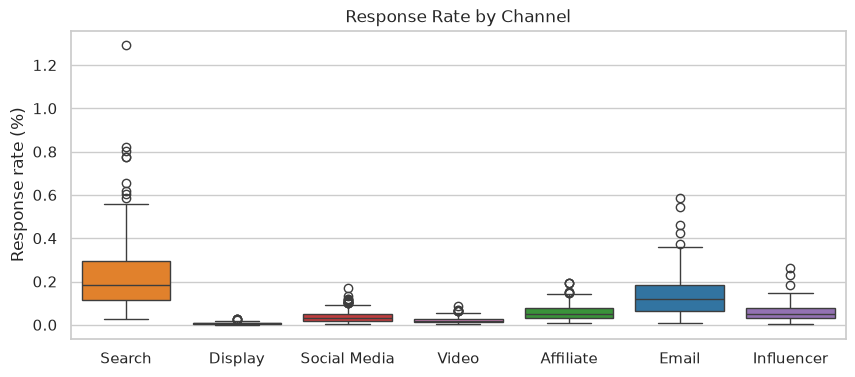

In [40]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="channel", y="response_rate", hue="channel", palette=channel_colors, legend=False)
plt.title("Response Rate by Channel")
plt.xlabel("")
plt.ylabel("Response rate (%)")
plt.savefig("../diagrams/02_response_rate_outliers.png", dpi=150, bbox_inches="tight")
plt.show()

In [41]:
Q1 = df["response_rate"].quantile(0.25)
Q3 = df["response_rate"].quantile(0.75)
IQR = Q3 - Q1
upper_rr = Q3 + 1.5 * IQR

print("Upper limit:", round(upper_rr, 4))
print("Outliers:", (df["response_rate"] > upper_rr).sum())

df.loc[df["response_rate"] > upper_rr, ["campaign_id", "channel", "campaign_type", "response_rate", "roi"]].head(10)

Upper limit: 0.2514
Outliers: 98


,campaign_id,channel,campaign_type,response_rate,roi
5,CMP-0311,Search,Retargeting,0.3305,1057.7
20,CMP-0740,Search,Lead Generation,0.3511,1375.9
23,CMP-0424,Email,Retargeting,0.3285,3798.9
25,CMP-1030,Search,Retargeting,0.4278,773.9
71,CMP-0760,Search,Lead Generation,0.3035,633.7
96,CMP-1165,Email,Retargeting,0.2741,1221.2
104,CMP-0057,Search,Seasonal Promo,0.2618,433.2
114,CMP-0592,Search,Retargeting,0.3900,1554.4
116,CMP-0794,Email,Seasonal Promo,0.3532,3852.6
118,CMP-0979,Search,Product Launch,0.2686,1086.5


**Decision:** these outliers are not mistakes. They are mostly email and search retargeting
campaigns that really worked very well. These are exactly the campaigns we want to learn from,
so we **keep them** in the data. (For budget, the outliers were typing mistakes, so we fixed them.)

### 3.3 Encoding and scaling

Machine learning models only understand numbers. So we make a second copy of the data
where text columns become numbers:
- **One-hot encoding** (`pd.get_dummies`): one new 0/1 column for each channel, region and audience.
  Used when the categories have no order.
- **Label encoding**: give each length group a number (1, 2, 3, 4). Used when the categories
  have an order.
- **Min-max scaling**: squeeze spend and impressions between 0 and 1, so big numbers
  (impressions in millions) do not look more important than small ones.
  Formula: (value - min) / (max - min)

In [42]:
encoded = df.copy()

# one-hot encoding
encoded = pd.get_dummies(encoded, columns=["channel", "region", "target_audience", "campaign_type"], dtype=int)

# label encoding (the order matters here)
length_order = {"1-2 weeks": 1, "3-4 weeks": 2, "1-2 months": 3, "2+ months": 4}
encoded["length_group"] = encoded["length_group"].map(length_order)

# min-max scaling
for col in ["budget", "spend", "impressions", "clicks", "conversions", "revenue"]:
    encoded[col] = (encoded[col] - encoded[col].min()) / (encoded[col].max() - encoded[col].min())

print("Columns before:", df.shape[1], " Columns after encoding:", encoded.shape[1])
encoded.head()

Columns before: 28  Columns after encoding: 47


,campaign_id,campaign_name,start_date,end_date,budget,spend,impressions,clicks,conversions,revenue,...,target_audience_Boomers (45-64),target_audience_Gen X (35-44),target_audience_Gen Z (18-24),target_audience_Millennials (25-34),target_audience_Unknown,campaign_type_Awareness,campaign_type_Lead Generation,campaign_type_Product Launch,campaign_type_Retargeting,campaign_type_Seasonal Promo
0,CMP-0542,Webinar - Search - NA,2023-07-26,2023-08-24,0.141519,0.161127,0.044513,0.064259,0.090129,0.064989,...,0,0,0,1,0,0,1,0,0,0
1,CMP-0260,Free Trial - Display - EU,2023-07-20,2023-08-18,0.063996,0.066432,0.200861,0.018405,0.008880,0.005061,...,0,0,1,0,0,0,1,0,0,0
2,CMP-0044,First Look - Social Media - NA,2023-07-12,2023-08-10,0.363684,0.336726,0.268226,0.430479,0.182329,0.161359,...,0,0,1,0,0,0,0,1,0,0
3,CMP-1009,Just Dropped - Video - NA,2023-04-25,2023-05-24,0.247659,0.254424,0.128579,0.137819,0.037887,0.031285,...,0,0,1,0,0,0,0,1,0,0
4,CMP-0585,Meet Us - Affiliate - NA,2024-08-07,2024-09-05,0.135276,0.126837,0.170050,0.134381,0.036703,0.034920,...,1,0,0,0,0,1,0,0,0,0


### 3.4 Save the cleaned data

In [43]:
print("Missing values:", df.isna().sum().sum())
print("Duplicates:", df.duplicated().sum())
print("Shape:", df.shape)

df.to_csv("../data/marketing_campaigns_clean.csv", index=False)
encoded.to_csv("../data/marketing_campaigns_encoded.csv", index=False)
print("Saved ../data/marketing_campaigns_clean.csv and ../data/marketing_campaigns_encoded.csv")

Missing values: 0
Duplicates: 0
Shape: (1200, 28)
Saved ../data/marketing_campaigns_clean.csv and ../data/marketing_campaigns_encoded.csv


## Step 4: Exploratory Data Analysis (EDA)

### 4.1 Overall performance

In [44]:
total_spend = df["spend"].sum()
total_revenue = df["revenue"].sum()
total_clicks = df["clicks"].sum()
total_conversions = df["conversions"].sum()
total_impressions = df["impressions"].sum()

print("Campaigns       :", len(df))
print("Total spend     :", round(total_spend), "$")
print("Total revenue   :", round(total_revenue), "$")
print("Overall ROI     :", round((total_revenue - total_spend) / total_spend * 100, 1), "%")
print("CTR             :", round(total_clicks / total_impressions * 100, 2), "%")
print("Conversion rate :", round(total_conversions / total_clicks * 100, 2), "%")
print("Average CPA     :", round(total_spend / total_conversions, 2), "$")
print("Profitable campaigns:", round((df["profit"] > 0).mean() * 100, 1), "%")

Campaigns       : 1200
Total spend     : 16184960 $
Total revenue   : 68069279 $
Overall ROI     : 320.6 %
CTR             : 1.54 %
Conversion rate : 3.51 %
Average CPA     : 19.52 $
Profitable campaigns: 83.3 %


In [45]:
df[["spend", "revenue", "ctr", "conversion_rate", "cpa", "roi", "engagement_score", "duration_days"]].describe().round(2)

,spend,revenue,ctr,conversion_rate,cpa,roi,engagement_score,duration_days
count,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00,1200.00
mean,13487.47,56724.40,2.08,3.37,41.91,418.37,5.63,28.28
std,10952.03,76015.74,1.40,2.42,48.23,669.00,2.33,20.47
min,1383.09,716.61,0.21,0.35,1.62,-81.60,1.00,7.00
25%,6028.60,13169.40,1.02,1.63,12.58,42.18,3.80,14.00
50%,10489.24,32273.90,1.67,2.64,25.30,194.65,5.20,21.00
75%,16797.47,65766.44,2.93,4.53,53.47,526.18,7.30,30.00
max,86404.70,709373.94,8.05,18.99,506.29,7449.40,10.00,90.00


### 4.2 A summary table for any group

**Important:** to get the CTR of a whole channel, we do **not** take the average of each
campaign's CTR. A tiny campaign would count as much as a huge one. Instead we **add up** all
clicks and all impressions of the channel first, and then divide.

We need this same table for channel, region, campaign type and audience, so instead of
copying the code 4 times we write it once as a **function**.

In [46]:
def make_summary(group_col):
    # add up the numbers for each group
    summary = df.groupby(group_col).agg(
        campaigns=("campaign_id", "count"),
        spend=("spend", "sum"),
        revenue=("revenue", "sum"),
        impressions=("impressions", "sum"),
        clicks=("clicks", "sum"),
        conversions=("conversions", "sum"),
    )
    # then calculate the rates from the totals
    summary["ctr"] = summary["clicks"] / summary["impressions"] * 100
    summary["conversion_rate"] = summary["conversions"] / summary["clicks"] * 100
    summary["cpa"] = summary["spend"] / summary["conversions"]
    summary["roi"] = (summary["revenue"] - summary["spend"]) / summary["spend"] * 100
    summary = summary.sort_values("roi", ascending=False).round(2)
    return summary.reset_index()


channel_summary = make_summary("channel")
channel_summary

,channel,campaigns,spend,revenue,impressions,clicks,conversions,ctr,conversion_rate,cpa,roi
0,Email,207,1192847.17,13383875.35,120818169,3228530,161645,2.67,5.01,7.38,1022.01
1,Affiliate,118,957607.83,6204551.49,123450604,1603252,74301,1.30,4.63,12.89,547.92
2,Search,213,3998138.65,22821738.33,136926379,5277112,279425,3.85,5.30,14.31,470.81
3,Social Media,248,3510148.53,13022323.38,404631902,6684712,158284,1.65,2.37,22.18,270.99
4,Influencer,122,1897686.78,5919170.26,125064855,2873499,75801,2.30,2.64,25.04,211.92
5,Display,164,1625396.05,2608831.48,409828538,1914042,30232,0.47,1.58,53.76,60.50
6,Video,128,3003134.99,4108788.40,218031917,2055503,49298,0.94,2.40,60.92,36.82


In [47]:
region_summary = make_summary("region")
region_summary

,region,campaigns,spend,revenue,impressions,clicks,conversions,ctr,conversion_rate,cpa,roi
0,Unknown,26,369069.37,2479966.56,30691801,606350,24970,1.98,4.12,14.78,571.95
1,North America,372,4734270.63,28254510.52,495800984,7293900,280644,1.47,3.85,16.87,496.81
2,Europe,338,4727001.73,18893894.54,449436936,6634043,218336,1.48,3.29,21.65,299.70
3,Asia Pacific,225,3145172.82,10740299.06,284155381,4650942,166750,1.64,3.59,18.86,241.49
4,Middle East & Africa,111,1511983.60,3652688.97,127167145,2209196,58981,1.74,2.67,25.64,141.58
5,Latin America,128,1697461.85,4047919.04,151500117,2242219,79305,1.48,3.54,21.40,138.47


In [48]:
type_summary = make_summary("campaign_type")
type_summary

,campaign_type,campaigns,spend,revenue,impressions,clicks,conversions,ctr,conversion_rate,cpa,roi
0,Retargeting,243,3247870.29,23781165.83,282799979,5401561,290192,1.91,5.37,11.19,632.21
1,Seasonal Promo,246,3302774.02,16385634.57,319710121,5056233,194037,1.58,3.84,17.02,396.12
2,Lead Generation,242,3206006.10,12231468.49,321369612,4449975,151390,1.38,3.40,21.18,281.52
3,Product Launch,226,3146385.73,11223630.11,303073100,4790003,136481,1.58,2.85,23.05,256.72
4,Awareness,243,3281923.86,4447379.69,311799552,3938878,56886,1.26,1.44,57.69,35.51


In [49]:
audience_summary = make_summary("target_audience")
audience_summary

,target_audience,campaigns,spend,revenue,impressions,clicks,conversions,ctr,conversion_rate,cpa,roi
0,Gen X (35-44),280,3699904.07,19975071.26,367800448,5322866,212198,1.45,3.99,17.44,439.88
1,Unknown,35,431121.01,2205698.72,36320600,621523,27675,1.71,4.45,15.58,411.62
2,Millennials (25-34),419,5716797.31,24917603.05,535629023,8050376,312918,1.50,3.89,18.27,335.87
3,Boomers (45-64),193,2589071.84,11282907.03,239690171,3355952,118923,1.40,3.54,21.77,335.79
4,Gen Z (18-24),273,3748065.77,9687998.63,359312122,6285933,157272,1.75,2.50,23.83,158.48


### 4.3 Campaign performance over time

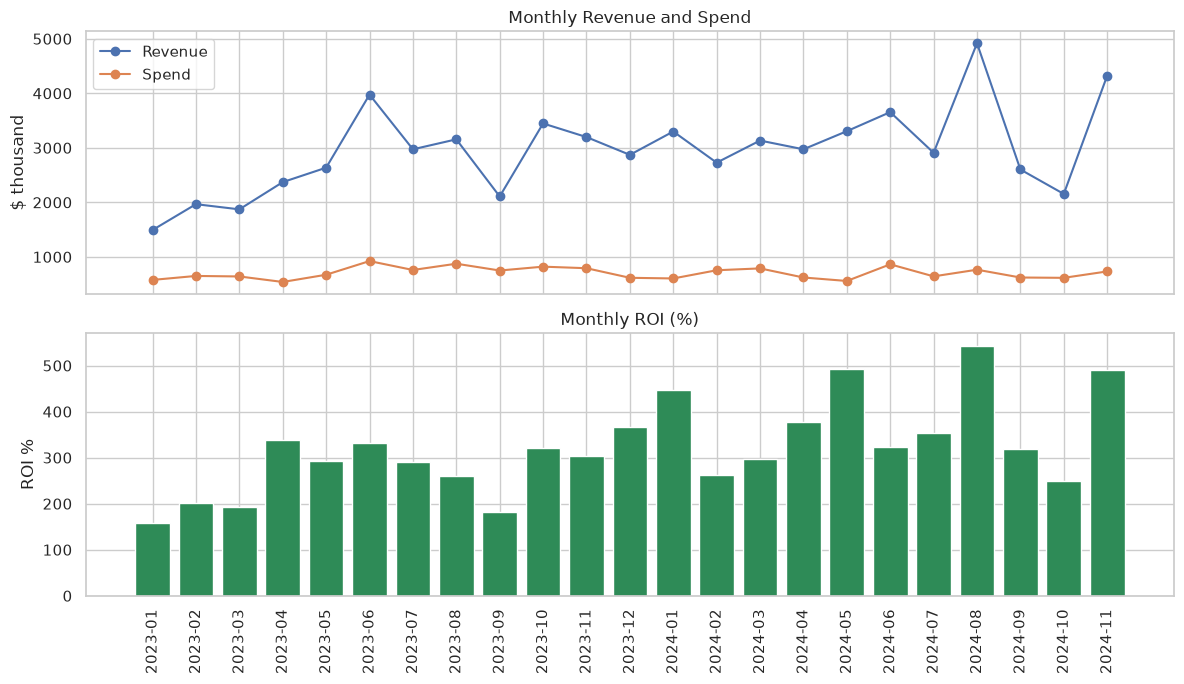

In [50]:
df["year_month"] = df["start_date"].dt.to_period("M").astype(str)

monthly = df.groupby("year_month").agg(spend=("spend", "sum"), revenue=("revenue", "sum")).reset_index()
monthly["roi"] = (monthly["revenue"] - monthly["spend"]) / monthly["spend"] * 100

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# divide by 1000 so the axis shows thousands instead of 1e6
axes[0].plot(monthly["year_month"], monthly["revenue"] / 1000, marker="o", label="Revenue")
axes[0].plot(monthly["year_month"], monthly["spend"] / 1000, marker="o", label="Spend")
axes[0].set_title("Monthly Revenue and Spend")
axes[0].set_ylabel("$ thousand")
axes[0].legend()

axes[1].bar(monthly["year_month"], monthly["roi"], color="seagreen")
axes[1].set_title("Monthly ROI (%)")
axes[1].set_ylabel("ROI %")
axes[1].tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.savefig("../diagrams/03_performance_over_time.png", dpi=150, bbox_inches="tight")
plt.show()

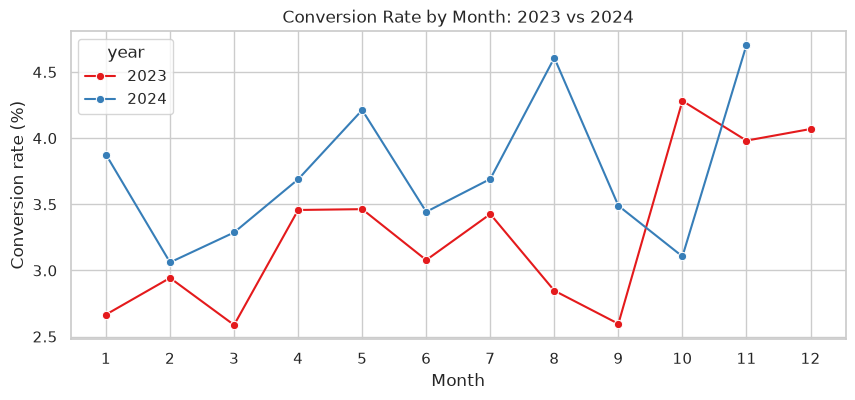

In [51]:
# conversion rate per month, one line per year (to see seasons)
by_month = df.groupby(["year", "month"]).agg(clicks=("clicks", "sum"), conversions=("conversions", "sum")).reset_index()
by_month["conversion_rate"] = by_month["conversions"] / by_month["clicks"] * 100

plt.figure(figsize=(10, 4))
sns.lineplot(data=by_month, x="month", y="conversion_rate", hue="year", marker="o", palette="Set1")
plt.title("Conversion Rate by Month: 2023 vs 2024")
plt.xlabel("Month")
plt.ylabel("Conversion rate (%)")
plt.xticks(range(1, 13))
plt.savefig("../diagrams/04_conversion_by_month.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.4 Compare channels

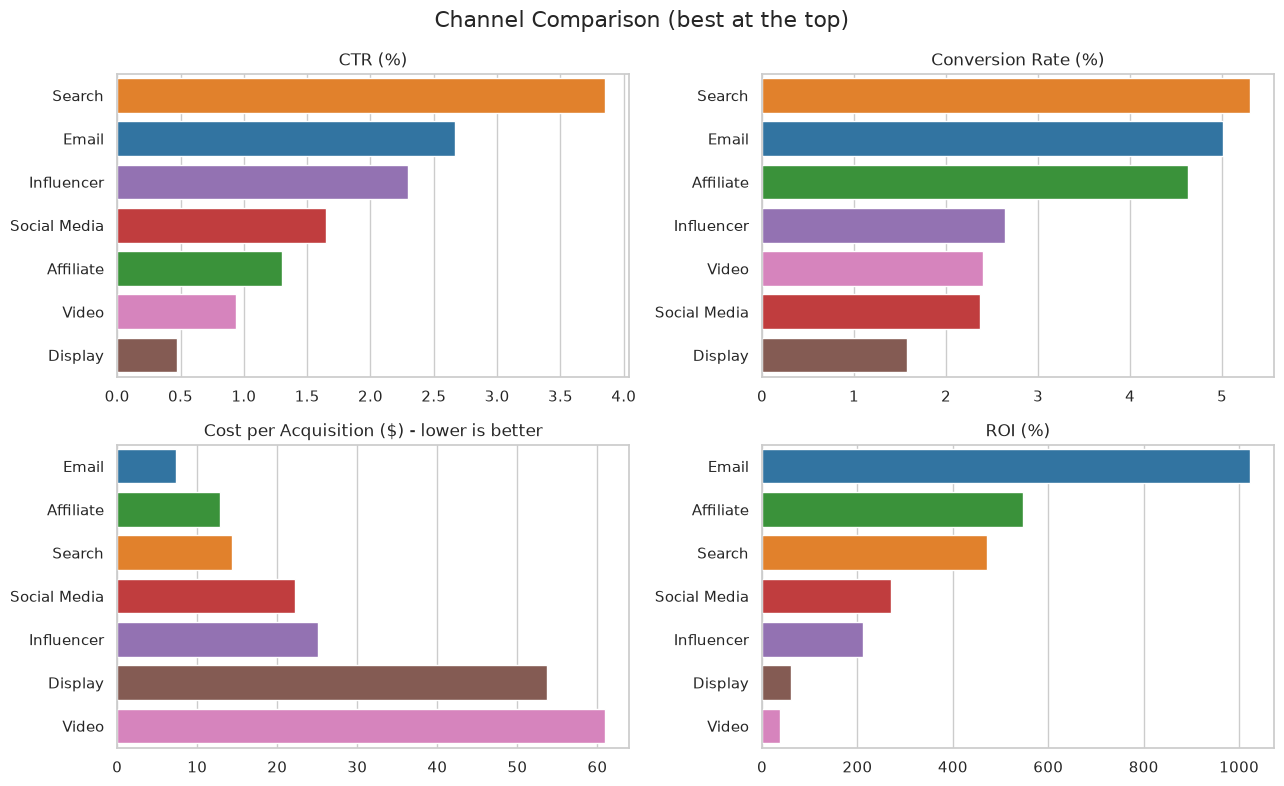

In [52]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

sns.barplot(data=channel_summary.sort_values("ctr", ascending=False), x="ctr", y="channel", hue="channel", palette=channel_colors, legend=False, ax=axes[0, 0])
axes[0, 0].set_title("CTR (%)")

sns.barplot(data=channel_summary.sort_values("conversion_rate", ascending=False), x="conversion_rate", y="channel", hue="channel", palette=channel_colors, legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Conversion Rate (%)")

sns.barplot(data=channel_summary.sort_values("cpa"), x="cpa", y="channel", hue="channel", palette=channel_colors, legend=False, ax=axes[1, 0])
axes[1, 0].set_title("Cost per Acquisition ($) - lower is better")

sns.barplot(data=channel_summary, x="roi", y="channel", hue="channel", palette=channel_colors, legend=False, ax=axes[1, 1])
axes[1, 1].set_title("ROI (%)")

for ax in axes.flat:
    ax.set_xlabel("")
    ax.set_ylabel("")

fig.suptitle("Channel Comparison (best at the top)", fontsize=16)
plt.tight_layout()
plt.savefig("../diagrams/05_channel_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

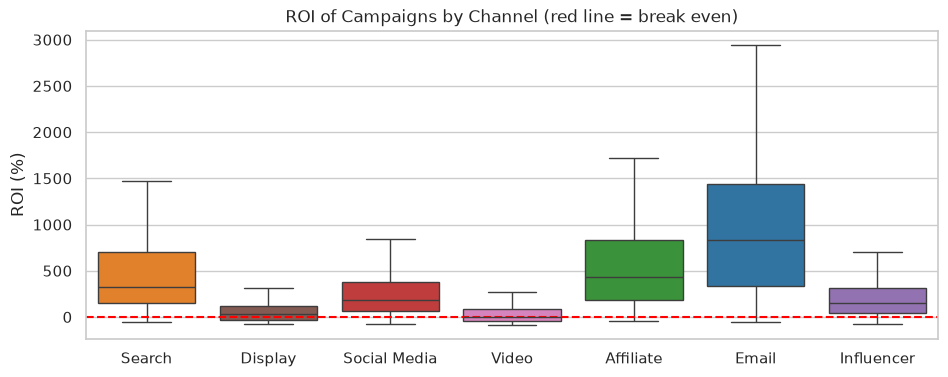

In [53]:
# ROI of every single campaign, per channel
plt.figure(figsize=(11, 4))
sns.boxplot(data=df, x="channel", y="roi", hue="channel", palette=channel_colors, legend=False, showfliers=False)
plt.axhline(0, color="red", linestyle="--")   # below this line the campaign lost money
plt.title("ROI of Campaigns by Channel (red line = break even)")
plt.xlabel("")
plt.ylabel("ROI (%)")
plt.savefig("../diagrams/06_roi_by_channel.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.5 Compare regions, campaign types and audiences

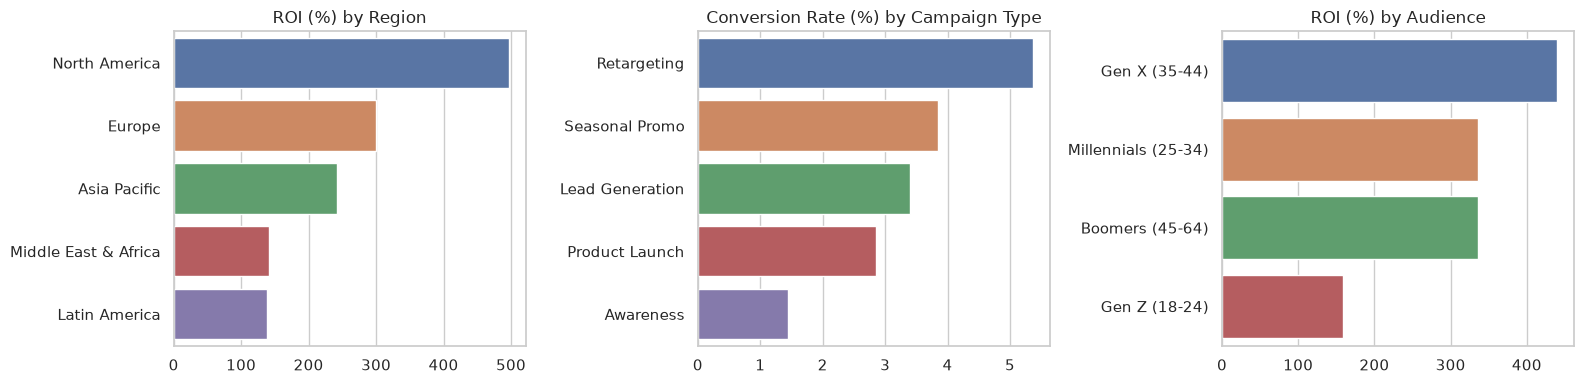

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

regions = region_summary.loc[region_summary["region"] != "Unknown"]
sns.barplot(data=regions, x="roi", y="region", hue="region", legend=False, ax=axes[0])
axes[0].set_title("ROI (%) by Region")

sns.barplot(data=type_summary, x="conversion_rate", y="campaign_type", hue="campaign_type", legend=False, ax=axes[1])
axes[1].set_title("Conversion Rate (%) by Campaign Type")

audiences = audience_summary.loc[audience_summary["target_audience"] != "Unknown"]
sns.barplot(data=audiences, x="roi", y="target_audience", hue="target_audience", legend=False, ax=axes[2])
axes[2].set_title("ROI (%) by Audience")

for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("")

plt.tight_layout()
plt.savefig("../diagrams/07_region_type_audience.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.6 Heatmaps: which channel works for which audience and region?

A pivot table with `aggfunc="sum"` adds up the clicks and impressions for every
channel + audience pair. Dividing the two tables gives the CTR of each pair.

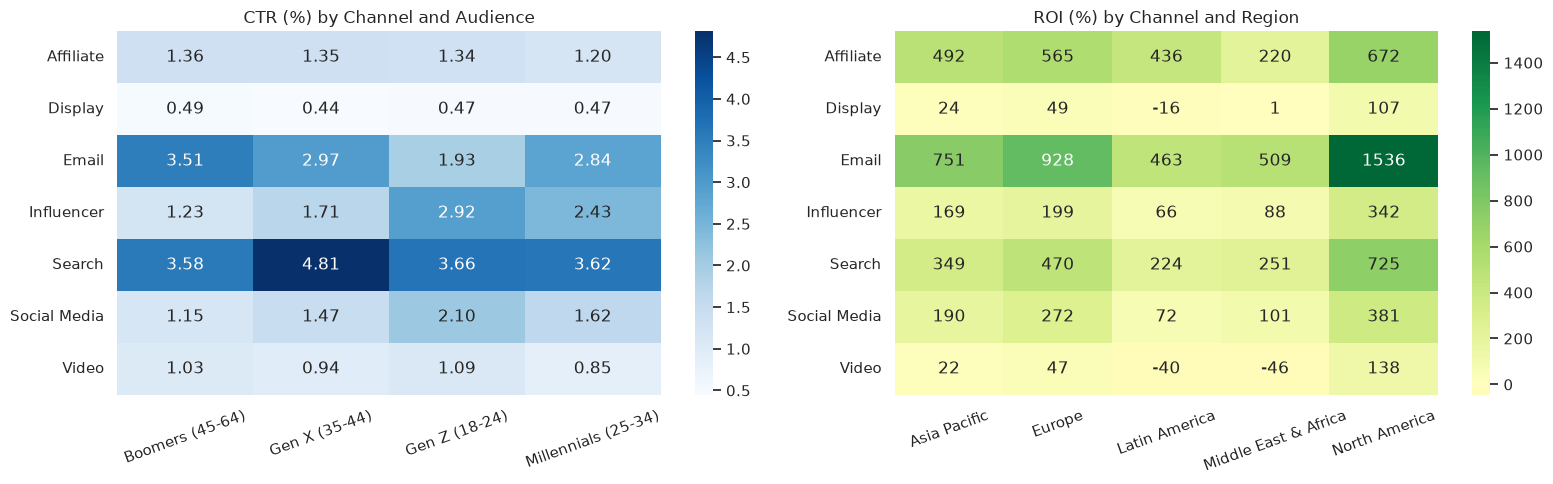

In [55]:
known = df.loc[(df["target_audience"] != "Unknown") & (df["region"] != "Unknown")]

clicks_pivot = known.pivot_table(index="channel", columns="target_audience", values="clicks", aggfunc="sum")
impressions_pivot = known.pivot_table(index="channel", columns="target_audience", values="impressions", aggfunc="sum")
ctr_pivot = clicks_pivot / impressions_pivot * 100

revenue_pivot = known.pivot_table(index="channel", columns="region", values="revenue", aggfunc="sum")
spend_pivot = known.pivot_table(index="channel", columns="region", values="spend", aggfunc="sum")
roi_pivot = (revenue_pivot - spend_pivot) / spend_pivot * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.heatmap(ctr_pivot, annot=True, fmt=".2f", cmap="Blues", ax=axes[0])
axes[0].set_title("CTR (%) by Channel and Audience")

sns.heatmap(roi_pivot, annot=True, fmt=".0f", cmap="RdYlGn", center=0, ax=axes[1])
axes[1].set_title("ROI (%) by Channel and Region")

for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig("../diagrams/08_heatmaps.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.7 Correlation between numbers

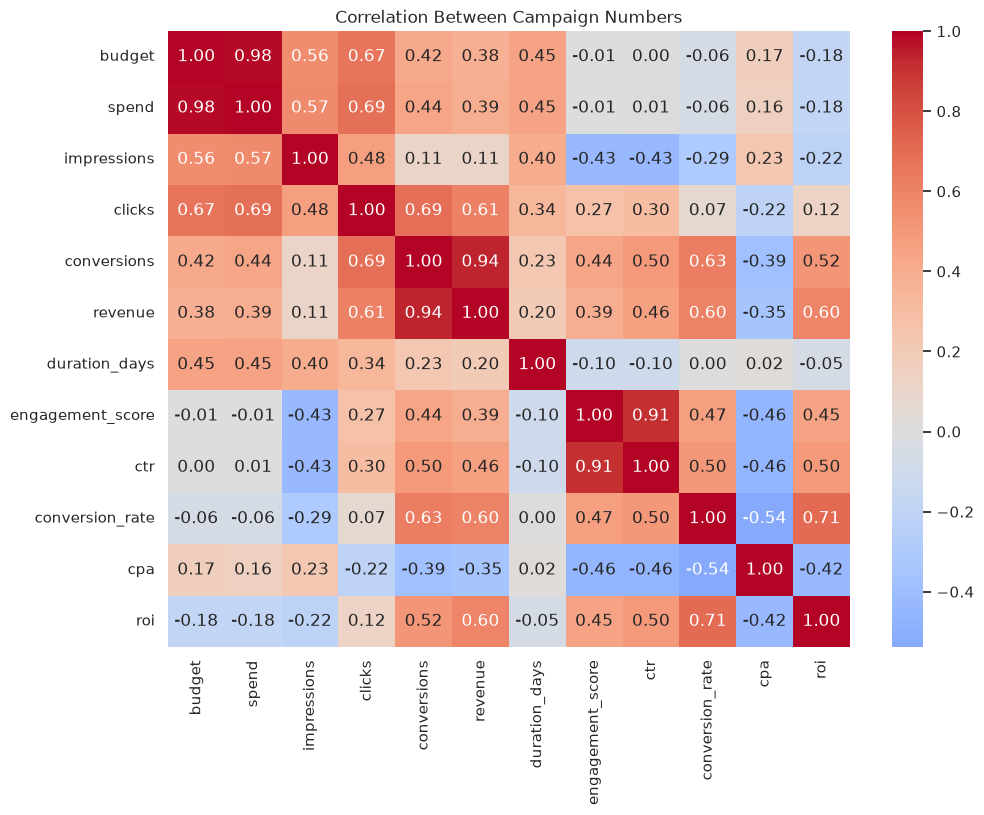

In [56]:
corr = df[["budget", "spend", "impressions", "clicks", "conversions", "revenue", "duration_days",
           "engagement_score", "ctr", "conversion_rate", "cpa", "roi"]].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Campaign Numbers")
plt.savefig("../diagrams/09_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

In [57]:
# which numbers move together with ROI?
corr["roi"].sort_values(ascending=False)

roi                 1.000000
conversion_rate     0.705412
revenue             0.595692
conversions         0.515349
ctr                 0.496403
engagement_score    0.451065
clicks              0.123897
duration_days      -0.053118
spend              -0.180170
budget             -0.183700
impressions        -0.221024
cpa                -0.424254
Name: roi, dtype: float64

**How to read this:** 1 means "go up together", -1 means "one goes up, the other goes down",
0 means "no relation".
- ROI goes up with **conversion rate** and goes down with **CPA**: cheap customers mean high profit.
- ROI has almost **no relation with spend or budget**: spending more does not make a campaign better.

### 4.8 Top and bottom campaigns

We only rank campaigns that spent at least the median amount, so a tiny test campaign
with lucky numbers does not take the first place.

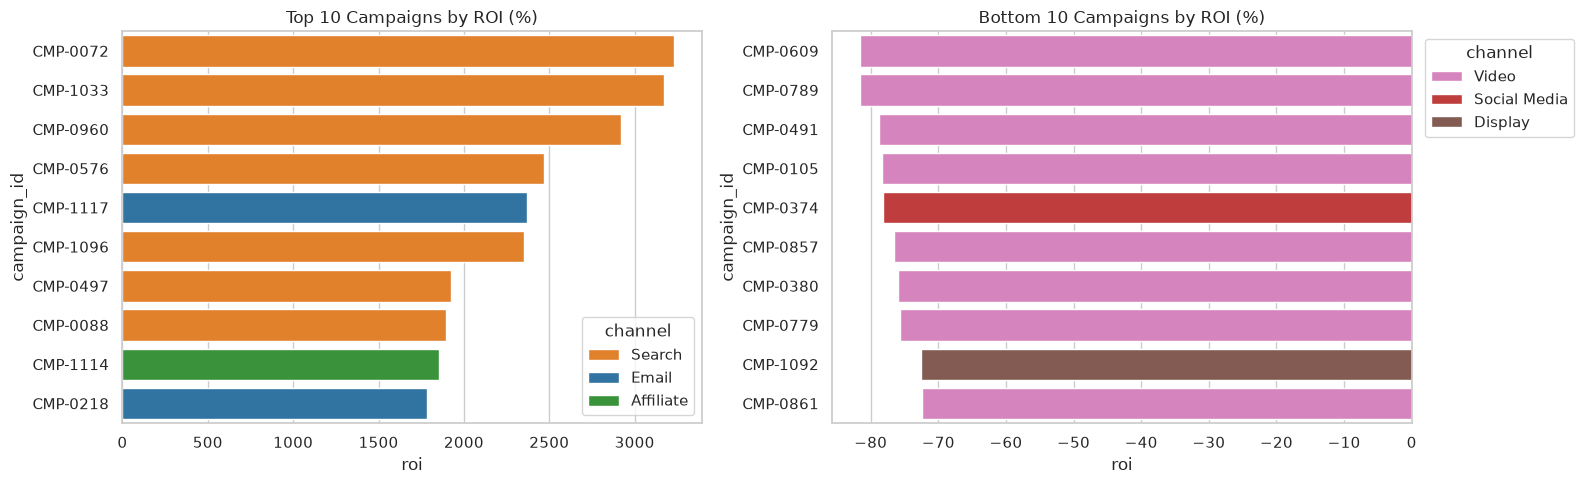

In [58]:
big_campaigns = df.loc[df["spend"] >= df["spend"].median()]

top10 = big_campaigns.sort_values("roi", ascending=False).head(10)
bottom10 = big_campaigns.sort_values("roi").head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(data=top10, x="roi", y="campaign_id", hue="channel", palette=channel_colors, dodge=False, ax=axes[0])
axes[0].set_title("Top 10 Campaigns by ROI (%)")

sns.barplot(data=bottom10, x="roi", y="campaign_id", hue="channel", palette=channel_colors, dodge=False, ax=axes[1])
axes[1].set_title("Bottom 10 Campaigns by ROI (%)")
axes[1].legend(title="channel", loc="upper left", bbox_to_anchor=(1.01, 1))   # put legend outside the bars

plt.tight_layout()
plt.savefig("../diagrams/10_top_bottom_campaigns.png", dpi=150, bbox_inches="tight")
plt.show()

In [59]:
top10[["campaign_id", "campaign_name", "campaign_type", "target_audience", "spend", "revenue", "roi"]]

,campaign_id,campaign_name,campaign_type,target_audience,spend,revenue,roi
511,CMP-0072,Last Chance - Search - EU,Retargeting,Gen X (35-44),21290.61,709373.94,3231.9
801,CMP-1033,Cart Reminder - Search - NA,Retargeting,Millennials (25-34),14219.40,465334.86,3172.5
416,CMP-0960,Holiday Deals - Search - NA,Seasonal Promo,Gen X (35-44),17520.13,529001.66,2919.4
567,CMP-0576,Cart Reminder - Search - EU,Retargeting,Millennials (25-34),11333.75,291178.52,2469.1
1106,CMP-1117,Summer Sale - Email - NA,Seasonal Promo,Millennials (25-34),10800.53,266613.23,2368.5
1214,CMP-1096,We Miss You - Search - NA,Retargeting,Gen X (35-44),20109.34,492997.19,2351.6
913,CMP-0497,Cart Reminder - Search - NA,Retargeting,Gen X (35-44),10499.43,212450.22,1923.4
1209,CMP-0088,Last Chance - Search - EU,Retargeting,Boomers (45-64),11568.74,230531.92,1892.7
1012,CMP-1114,Last Chance - Affiliate - NA,Retargeting,Boomers (45-64),13270.69,259523.48,1855.6
769,CMP-0218,Cart Reminder - Email - EU,Retargeting,Millennials (25-34),27607.14,519638.96,1782.3


In [60]:
bottom10[["campaign_id", "campaign_name", "campaign_type", "target_audience", "spend", "revenue", "roi"]]

,campaign_id,campaign_name,campaign_type,target_audience,spend,revenue,roi
1046,CMP-0609,Hello World - Video - EU,Awareness,Millennials (25-34),53160.97,9763.91,-81.6
184,CMP-0789,Brand Story - Video - MEA,Awareness,Gen X (35-44),27443.34,5043.26,-81.6
225,CMP-0491,Meet Us - Video - APAC,Awareness,Gen Z (18-24),35901.14,7598.83,-78.8
534,CMP-0105,Free Trial - Video - LATAM,Lead Generation,Gen Z (18-24),44653.89,9672.43,-78.3
544,CMP-0374,Discover - Social Media - LATAM,Awareness,Gen Z (18-24),11636.30,2532.05,-78.2
1194,CMP-0857,Discover - Video - MEA,Awareness,Gen Z (18-24),42194.07,9923.67,-76.5
1139,CMP-0380,Meet Us - Video - LATAM,Awareness,Gen X (35-44),14923.38,3575.58,-76.0
113,CMP-0779,Discover - Video - APAC,Awareness,Boomers (45-64),12138.83,2962.74,-75.6
345,CMP-1092,Meet Us - Display - APAC,Awareness,Millennials (25-34),17825.24,4890.51,-72.6
1216,CMP-0861,Hello World - Video - MEA,Awareness,Millennials (25-34),59701.61,16472.83,-72.4


## Step 5: Answering the Business Questions

#### Q1. Which channel gives the best return on the money spent?

In [61]:
channel_summary[["channel", "spend", "revenue", "cpa", "roi"]]

,channel,spend,revenue,cpa,roi
0,Email,1192847.17,13383875.35,7.38,1022.01
1,Affiliate,957607.83,6204551.49,12.89,547.92
2,Search,3998138.65,22821738.33,14.31,470.81
3,Social Media,3510148.53,13022323.38,22.18,270.99
4,Influencer,1897686.78,5919170.26,25.04,211.92
5,Display,1625396.05,2608831.48,53.76,60.50
6,Video,3003134.99,4108788.40,60.92,36.82


**Answer:** **Email** gives the best return by far: ROI **1,022 %** (every \$1 spent brings back about \$11)
and one customer costs only **\$7.38**. **Affiliate** (ROI 548 %, CPA \$12.89) and **Search** (ROI 471 %,
CPA \$14.31) come next. **Video** is the weakest: ROI only 37 % and one customer costs **\$60.92**,
about 8 times more than through email.

#### Q2. Which channels take a big part of the budget but bring little profit?

In [62]:
share = channel_summary[["channel", "spend", "revenue"]].copy()
share["profit"] = share["revenue"] - share["spend"]
share["spend_share_%"] = (share["spend"] / share["spend"].sum() * 100).round(1)
share["profit_share_%"] = (share["profit"] / share["profit"].sum() * 100).round(1)
share

,channel,spend,revenue,profit,spend_share_%,profit_share_%
0,Email,1192847.17,13383875.35,12191028.18,7.4,23.5
1,Affiliate,957607.83,6204551.49,5246943.66,5.9,10.1
2,Search,3998138.65,22821738.33,18823599.68,24.7,36.3
3,Social Media,3510148.53,13022323.38,9512174.85,21.7,18.3
4,Influencer,1897686.78,5919170.26,4021483.48,11.7,7.8
5,Display,1625396.05,2608831.48,983435.43,10.0,1.9
6,Video,3003134.99,4108788.40,1105653.41,18.6,2.1


**Answer:** **Video and Display.** Together they use **28.6 %** of the whole budget
(18.6 % + 10.0 %) but bring only **4.0 %** of the profit (2.1 % + 1.9 %).
The opposite is Email: only 7.4 % of the budget but **23.5 %** of the profit. Search is the biggest profit
maker overall with **36.3 %** of the profit from 24.7 % of the budget.

#### Q3. Which campaign type works best, and which one wastes money?

In [63]:
type_summary[["campaign_type", "spend", "conversion_rate", "cpa", "roi"]]

,campaign_type,spend,conversion_rate,cpa,roi
0,Retargeting,3247870.29,5.37,11.19,632.21
1,Seasonal Promo,3302774.02,3.84,17.02,396.12
2,Lead Generation,3206006.10,3.40,21.18,281.52
3,Product Launch,3146385.73,2.85,23.05,256.72
4,Awareness,3281923.86,1.44,57.69,35.51


In [64]:
# awareness campaigns on video and display: how much did we spend and what did we get back?
waste = df.loc[(df["campaign_type"] == "Awareness") & (df["channel"].isin(["Video", "Display"]))]
print("Campaigns:", len(waste))
print("Spend:", round(waste["spend"].sum()))
print("ROI:", round((waste["revenue"].sum() - waste["spend"].sum()) / waste["spend"].sum() * 100, 1), "%")

Campaigns: 59
Spend: 877162
ROI: -44.5 %


**Answer:** **Retargeting** works best (showing ads again to people who already visited or left
something in their cart): conversion rate **5.37 %**, CPA \$11.19, ROI **632 %**.
**Awareness** campaigns are the weakest: conversion rate 1.44 %, CPA \$57.69, ROI only 36 %.
The real waste is **awareness campaigns on Video and Display**: 59 campaigns, **\$877,162** spent,
ROI **-44.5 %**, so we got back only about half of the money.

#### Q4. Do more clicks mean more sales?

In [65]:
channel_summary[["channel", "ctr", "conversion_rate", "roi"]].sort_values("ctr", ascending=False)

,channel,ctr,conversion_rate,roi
2,Search,3.85,5.30,470.81
0,Email,2.67,5.01,1022.01
4,Influencer,2.30,2.64,211.92
3,Social Media,1.65,2.37,270.99
1,Affiliate,1.30,4.63,547.92
6,Video,0.94,2.40,36.82
5,Display,0.47,1.58,60.50


In [66]:
print("Correlation of ROI with CTR            :", round(df["roi"].corr(df["ctr"]), 2))
print("Correlation of ROI with conversion rate:", round(df["roi"].corr(df["conversion_rate"]), 2))

Correlation of ROI with CTR            : 0.5
Correlation of ROI with conversion rate: 0.71


**Answer:** **Not always.** Influencer gets more clicks than Affiliate (CTR 2.30 % vs 1.30 %),
but Affiliate turns many more clicks into customers (4.63 % vs 2.64 %) and has more than double the ROI
(548 % vs 212 %). The correlation tells the same story: ROI is more connected to **conversion rate (0.71)**
than to **CTR (0.50)**. So campaigns should be judged on conversions and cost per customer, not on clicks.

#### Q5. Which audience responds best, and to which channel?

In [67]:
audience_summary[["target_audience", "ctr", "conversion_rate", "roi"]]

,target_audience,ctr,conversion_rate,roi
0,Gen X (35-44),1.45,3.99,439.88
1,Unknown,1.71,4.45,411.62
2,Millennials (25-34),1.50,3.89,335.87
3,Boomers (45-64),1.40,3.54,335.79
4,Gen Z (18-24),1.75,2.50,158.48


In [68]:
ctr_pivot.round(2)

target_audience,Boomers (45-64),Gen X (35-44),Gen Z (18-24),Millennials (25-34)
channel,,,,
Affiliate,1.36,1.35,1.34,1.20
Display,0.49,0.44,0.47,0.47
Email,3.51,2.97,1.93,2.84
Influencer,1.23,1.71,2.92,2.43
Search,3.58,4.81,3.66,3.62
Social Media,1.15,1.47,2.10,1.62
Video,1.03,0.94,1.09,0.85


**Answer:** **Gen X** gives the best ROI (**440 %**). **Gen Z** clicks the most (CTR 1.75 %) but
buys the least (conversion 2.50 %), so it has the lowest ROI (**158 %**).
Each age group likes a different channel:
- **Gen Z** clicks on **Influencer** (2.92 %) and **Social Media** (2.10 %) much more than Boomers do (1.23 % and 1.15 %).
- **Boomers** respond best to **Email** (3.51 %, vs only 1.93 % for Gen Z).
- **Gen X** responds best to **Search** (4.81 %).

#### Q6. Which regions perform best and worst?

In [69]:
region_summary[["region", "revenue", "conversion_rate", "cpa", "roi"]]

,region,revenue,conversion_rate,cpa,roi
0,Unknown,2479966.56,4.12,14.78,571.95
1,North America,28254510.52,3.85,16.87,496.81
2,Europe,18893894.54,3.29,21.65,299.70
3,Asia Pacific,10740299.06,3.59,18.86,241.49
4,Middle East & Africa,3652688.97,2.67,25.64,141.58
5,Latin America,4047919.04,3.54,21.40,138.47


In [70]:
roi_pivot.round(0)

region,Asia Pacific,Europe,Latin America,Middle East & Africa,North America
channel,,,,,
Affiliate,492.0,565.0,436.0,220.0,672.0
Display,24.0,49.0,-16.0,1.0,107.0
Email,751.0,928.0,463.0,509.0,1536.0
Influencer,169.0,199.0,66.0,88.0,342.0
Search,349.0,470.0,224.0,251.0,725.0
Social Media,190.0,272.0,72.0,101.0,381.0
Video,22.0,47.0,-40.0,-46.0,138.0


**Answer:** **North America** is the best region: ROI **497 %**, the cheapest customers (\$16.87)
and **41 %** of all revenue (\$28.3M of \$68.1M). **Latin America** (ROI 138 %) and **Middle East & Africa**
(ROI 142 %, CPA \$25.64) are the weakest. In these two regions **Video loses money** (ROI -40 % and -46 %)
and Display only breaks even or loses (-16 % and +1 %).

#### Q7. Is there a best time of year to run campaigns?

In [71]:
season = df.groupby("month_name").agg(clicks=("clicks", "sum"), conversions=("conversions", "sum"), month=("month", "first"))
season["conversion_rate"] = (season["conversions"] / season["clicks"] * 100).round(2)
season.sort_values("month")

,clicks,conversions,month,conversion_rate
month_name,,,,
January,1726327,58714,1,3.40
February,1956704,58879,2,3.01
March,2034306,60898,3,2.99
April,1884302,67576,4,3.59
May,1784267,68338,5,3.83
June,2780585,90181,6,3.24
July,1992089,70825,7,3.56
August,2516795,92155,8,3.66
September,2090368,63597,9,3.04


**Answer:** **Yes.** Campaigns that start in **November (4.34 %)** and **December (4.07 %)** convert the
best, because of holiday shopping. **February, March and September** are the slowest (about 3.0 %).
(Note: December has fewer campaigns because the 2024 data ends in early December.)

#### Q8. Do longer campaigns perform better?

In [72]:
length = make_summary("length_group")
length[["length_group", "campaigns", "ctr", "conversion_rate", "roi"]]

,length_group,campaigns,ctr,conversion_rate,roi
0,1-2 weeks,460,1.63,3.43,346.69
1,3-4 weeks,452,1.61,3.48,332.75
2,1-2 months,228,1.41,3.71,308.11
3,2+ months,60,1.37,3.20,238.09


**Answer:** **No, it is the opposite.** ROI goes down as campaigns get longer:
1-2 weeks **347 %** → 3-4 weeks 333 % → 1-2 months 308 % → 2+ months **238 %**.
CTR also drops from 1.63 % to 1.37 %. People get bored of seeing the same ad (this is called **ad fatigue**).

#### Q9. Did our marketing get better from 2023 to 2024?

In [73]:
year_summary = make_summary("year")
year_summary[["year", "campaigns", "spend", "revenue", "conversion_rate", "cpa", "roi"]]

,year,campaigns,spend,revenue,conversion_rate,cpa,roi
0,2024,569,7568240.09,36001938.83,3.74,17.45,375.70
1,2023,631,8616719.91,32067339.86,3.28,21.80,272.15


**Answer:** **Yes.** In 2024 we spent **less** (\$7.57M vs \$8.62M) but earned **more** (\$36.0M vs \$32.1M).
Conversion rate went up from 3.28 % to **3.74 %**, cost per customer went down from \$21.80 to **\$17.45**, and
ROI went up from 272 % to **376 %**.

#### Q10. What do the best and worst campaigns have in common?

In [74]:
best = df.sort_values("roi", ascending=False).head(120)    # top 10 % of 1,200 campaigns
worst = df.sort_values("roi").head(120)                    # bottom 10 %

print("TOP 10 % - channel")
print(best["channel"].value_counts(normalize=True).mul(100).round(1))
print("\nTOP 10 % - campaign type")
print(best["campaign_type"].value_counts(normalize=True).mul(100).round(1))

TOP 10 % - channel
channel
Email           62.5
Search          21.7
Affiliate       11.7
Social Media     3.3
Influencer       0.8
Name: proportion, dtype: float64

TOP 10 % - campaign type
campaign_type
Retargeting        45.0
Seasonal Promo     29.2
Product Launch     12.5
Lead Generation    12.5
Awareness           0.8
Name: proportion, dtype: float64


In [75]:
print("BOTTOM 10 % - channel")
print(worst["channel"].value_counts(normalize=True).mul(100).round(1))
print("\nBOTTOM 10 % - campaign type")
print(worst["campaign_type"].value_counts(normalize=True).mul(100).round(1))

BOTTOM 10 % - channel
channel
Video           36.7
Display         34.2
Influencer      12.5
Social Media    11.7
Search           2.5
Email            1.7
Affiliate        0.8
Name: proportion, dtype: float64

BOTTOM 10 % - campaign type
campaign_type
Awareness          60.0
Lead Generation    12.5
Product Launch     12.5
Seasonal Promo     10.8
Retargeting         4.2
Name: proportion, dtype: float64


**Answer:** There is a clear pattern:
- **Best 10 %:** 96 % are Email, Search or Affiliate (62.5 % Email alone), and 74 % are Retargeting or
  Seasonal Promo campaigns. Almost none are Awareness (0.8 %).
- **Worst 10 %:** 71 % are Video or Display, and 60 % are Awareness campaigns.

So **the right channel + a campaign that asks people to buy** wins, and **Video/Display + awareness** loses.

## Step 6: Summary and Recommendations

### What we found
- Overall the campaigns are profitable: **\$16.2M spent → \$68.1M revenue** (ROI 321 %), and 83 % of campaigns made a profit.
- But the results are very uneven. **Channel** and **campaign type** decide most of the success.
- **Email, Search and Affiliate** are the strongest channels. **Video and Display** take 29 % of the budget but bring only 4 % of the profit.
- **Retargeting** is the best campaign type. **Awareness** is the weakest, and on Video/Display it loses money.
- Clicks are not the same as sales: Gen Z, Social Media and Influencer get many clicks but fewer customers.
- **North America** performs best. Video and Display lose money in **Latin America** and **Middle East & Africa**.
- **November-December** are the best months. Campaigns longer than 2 months perform worse.
- Performance improved a lot from 2023 to 2024.

### Recommendations
1. **Move budget from Video and Display to Email, Search and Affiliate.** Test it first with part of the budget.
2. **Run more retargeting campaigns**, especially on Email and Search (cart reminders, "last chance", "we miss you").
3. **Stop Video and Display in Latin America and Middle East & Africa**, and use them only for brand awareness in North America and Europe.
4. **Pick the channel by audience:** Influencer and Social Media for Gen Z, Email for Boomers, Search for Gen X.
5. **Spend more in October-December** and less in February-March.
6. **Keep campaigns to about one month**, or change the ad design every 3-4 weeks.
7. **Judge campaigns by cost per customer (CPA) and conversion rate**, not by clicks.
8. **Fix the data entry:** use drop-down lists for channel and region and number-only budget fields, so the next analysis needs less cleaning.

*Note: the data was simulated for this task (see README), so these findings show the method, not facts about a real company.*